In [3]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

In [4]:
X, y = make_circles(n_samples=100, noise=0.1, random_state=1)

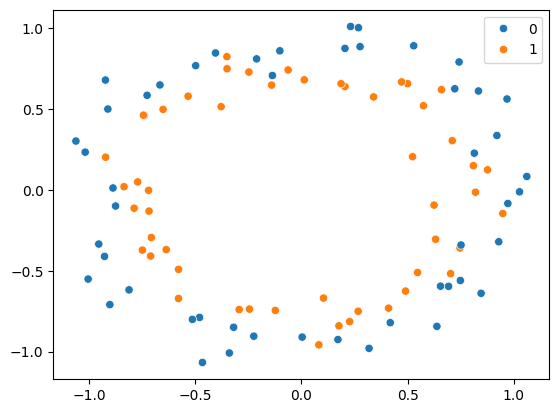

In [6]:
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y)
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2)

In [9]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Sequential

model = Sequential()

model.add(Input(shape=(2,)))
model.add(Dense(256, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [10]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [15]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, verbose=0)

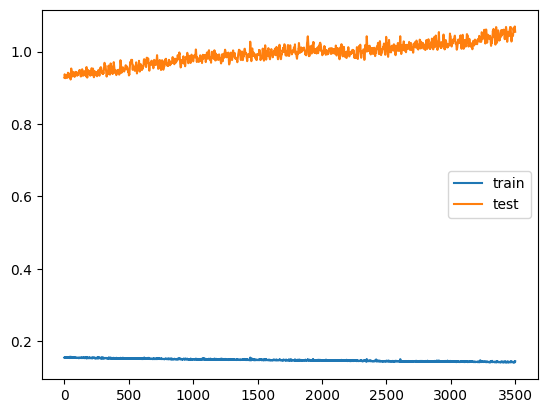

In [16]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

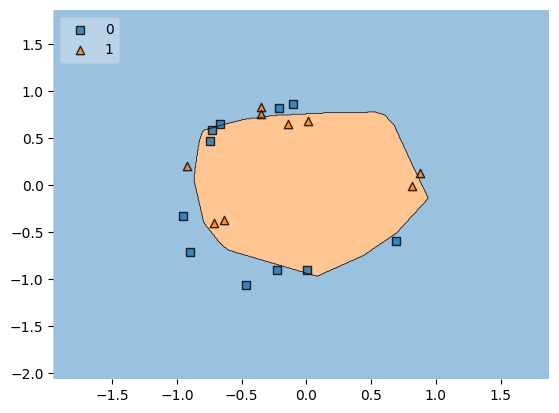

In [18]:
class KerasClassifierWrapper:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        probabilities = self.model.predict(X, verbose=0).ravel()
        return (probabilities >= 0.5).astype(int)

clf = KerasClassifierWrapper(model)

plot_decision_regions(X_test, y_test.ravel(), clf=clf, legend=2)
plt.show()

# Early Stopping


In [26]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [27]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [28]:
callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [29]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.4750 - loss: 0.6913 - val_accuracy: 0.5000 - val_loss: 0.6902
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4875 - loss: 0.6890 - val_accuracy: 0.4000 - val_loss: 0.6927
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5250 - loss: 0.6877 - val_accuracy: 0.5500 - val_loss: 0.6938
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5125 - loss: 0.6861 - val_accuracy: 0.5500 - val_loss: 0.6950
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4875 - loss: 0.6853 - val_accuracy: 0.5500 - val_loss: 0.6958
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5000 - loss: 0.6845 - val_accuracy: 0.5500 - val_loss: 0.6981
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5750 - loss: 0.6837 - val_accuracy: 0.5000 - val_loss: 0.6996
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5750 - loss: 0.6828 - val_accuracy: 0.4500 - v

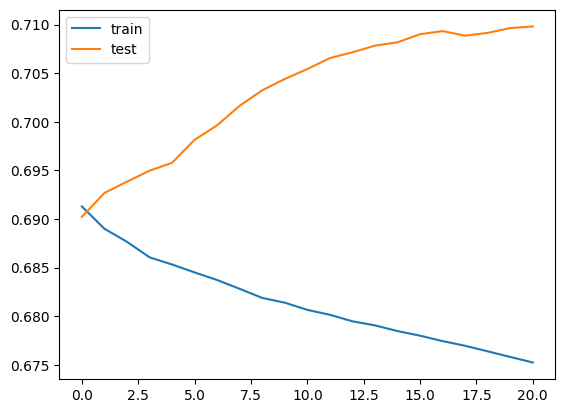

In [30]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 5s 526us/step


TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

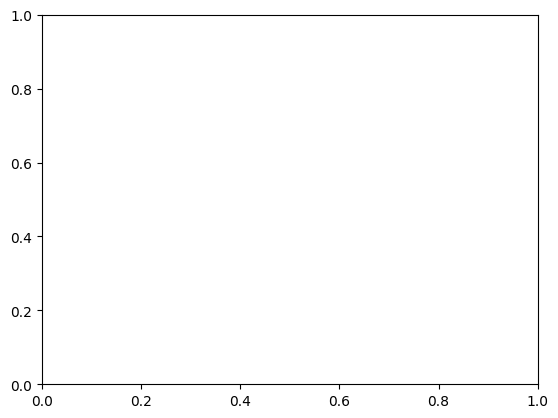

In [34]:
plot_decision_regions(
    X_test.astype(np.float64),
    np.asarray(y_test).ravel().astype(int),
    clf=model,
    legend=2
)
plt.show()

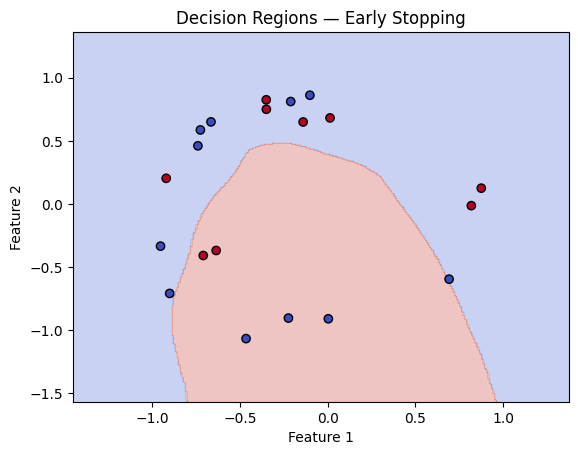

In [33]:
# Create a grid covering the feature space
x_min, x_max = X_test[:, 0].min() - 0.5, X_test[:, 0].max() + 0.5
y_min, y_max = X_test[:, 1].min() - 0.5, X_test[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict for every point in the grid
grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid, verbose=0)
Z = (Z >= 0.5).astype(int).reshape(xx.shape)

# Plot decision regions and test samples
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(
    X_test[:, 0], X_test[:, 1],
    c=np.asarray(y_test).ravel(),
    cmap='coolwarm',
    edgecolors='black'
)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Decision Regions — Early Stopping')
plt.show()